Heatmaps and clustered matrices-->07
--

In [62]:
import pandas as pd
import numpy as np
from numpy.random import randn
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats

**seaborn dataset**

In [65]:
flight_dframe = sns.load_dataset('flights')

In [67]:
flight_dframe.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [69]:
# pivot
flight_dframe = flight_dframe.pivot(columns='year',index='month',values='passengers')

In [71]:
flight_dframe

year,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
month,,,,,,,,,,,,
Jan,112,115,145,171,196,204,242,284,315,340,360,417
Feb,118,126,150,180,196,188,233,277,301,318,342,391
Mar,132,141,178,193,236,235,267,317,356,362,406,419
Apr,129,135,163,181,235,227,269,313,348,348,396,461
May,121,125,172,183,229,234,270,318,355,363,420,472
Jun,135,149,178,218,243,264,315,374,422,435,472,535
Jul,148,170,199,230,264,302,364,413,465,491,548,622
Aug,148,170,199,242,272,293,347,405,467,505,559,606
Sep,136,158,184,209,237,259,312,355,404,404,463,508


<Axes: xlabel='year', ylabel='month'>

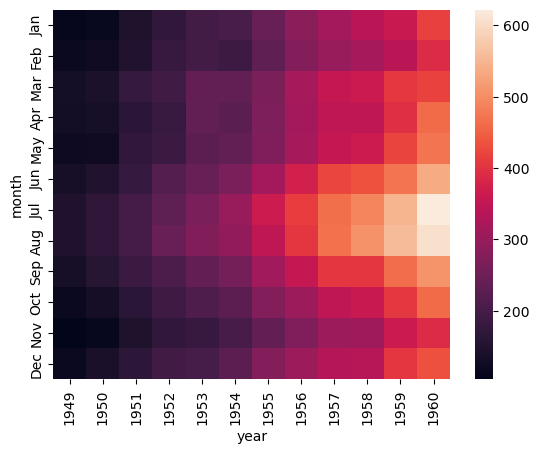

In [83]:
sns.heatmap(flight_dframe)

**annotate each cell with num passenger**

<Axes: xlabel='year', ylabel='month'>

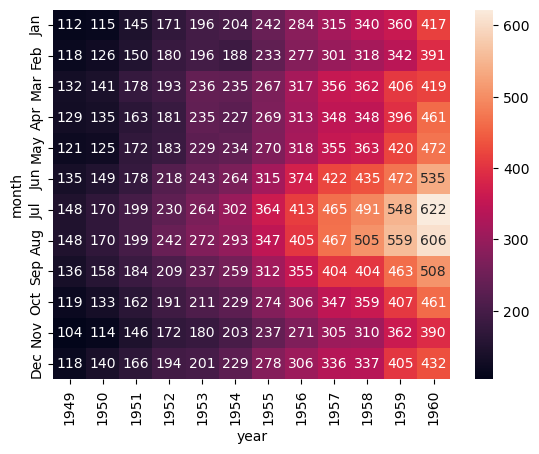

In [99]:
# fmt: format
sns.heatmap(flight_dframe,annot=True,fmt='d')
# fmt='d'   # integer
# fmt='.2f' # float با 2 رقم اعشار
# fmt='.1f' # float با 1 رقم اعشار

**covergence/divergence/centered colormap**

light to dark--> convergence

dark to light-->divergence🙂

**choose center for color schemes**

**`center`:** Sets the value that is treated as the center of the heatmap's color scale.


For example, `center=300` makes 300 the center of the color scale, so values below and above 300 are colored relative to it.


<Axes: xlabel='year', ylabel='month'>

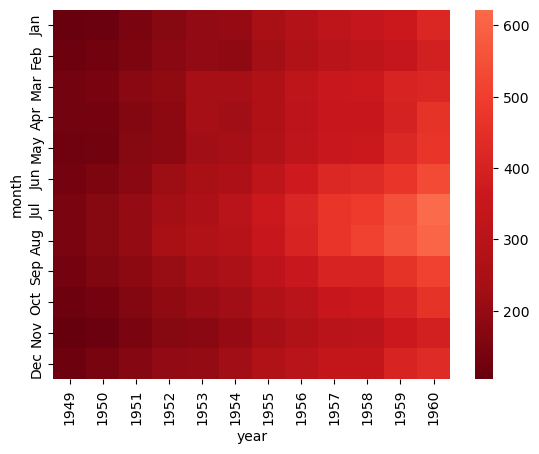

In [124]:
sns.heatmap(flight_dframe,center=flight_dframe.loc['Jul',1960],cmap='Reds_r')

**figure of multiple subplots**

<Axes: xlabel='year', ylabel='month'>

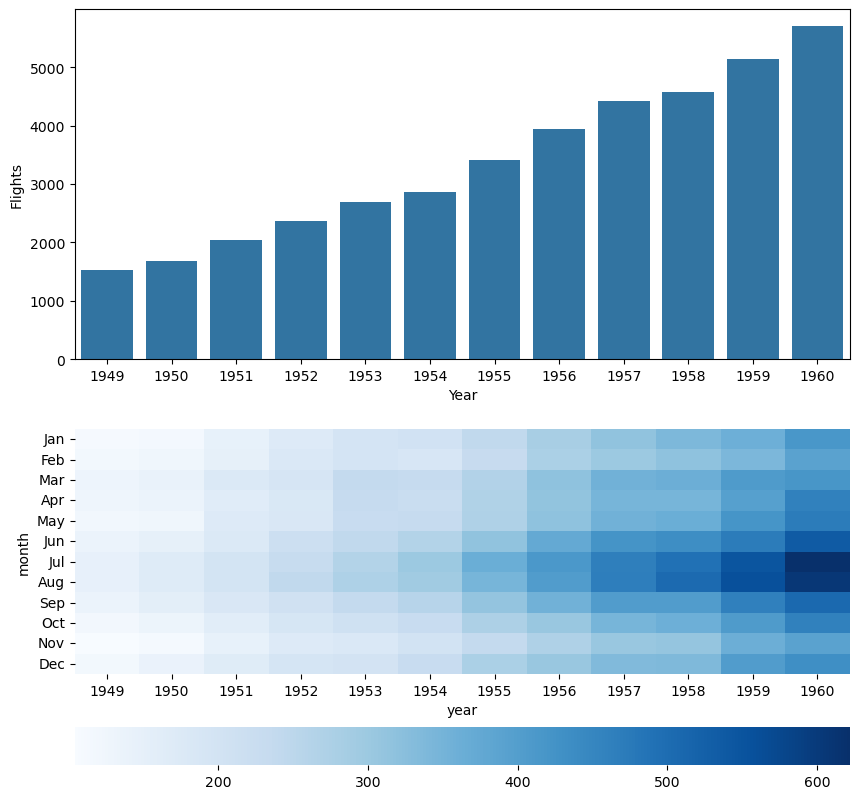

In [201]:
# 2 rows and 1 column
f , (axis1,axis2) = plt.subplots(2,1,figsize=(10, 10))
# sum of columns -->series
yearly_flights = flight_dframe.sum()
yearly_flights

years = pd.Series(yearly_flights.index.values)
years = pd.DataFrame(years)

flights = pd.Series(yearly_flights.values)
flights = pd.DataFrame(flights)

year_dframe = pd.concat((years,flights),axis=1)
year_dframe.columns = ['Year','Flights']
year_dframe

sns.barplot(x='Year',y='Flights',data=year_dframe,ax=axis1)

sns.heatmap(flight_dframe,cmap='Blues',ax=axis2,cbar_kws={'orientation':'horizontal'})

**clustermap**
it reformat the heatmap.similar rows are next to each other. and they are grouping and linking

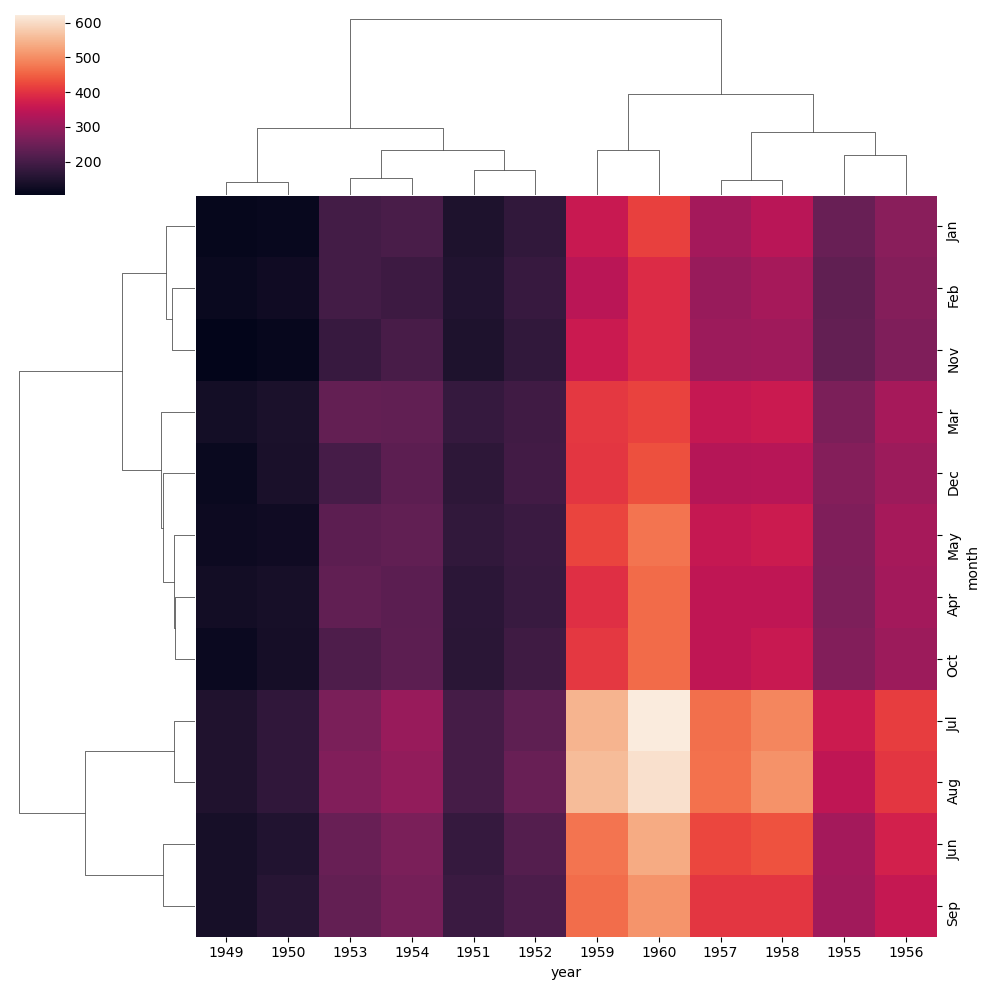

In [204]:
sns.clustermap(flight_dframe)

**uncluster columns**

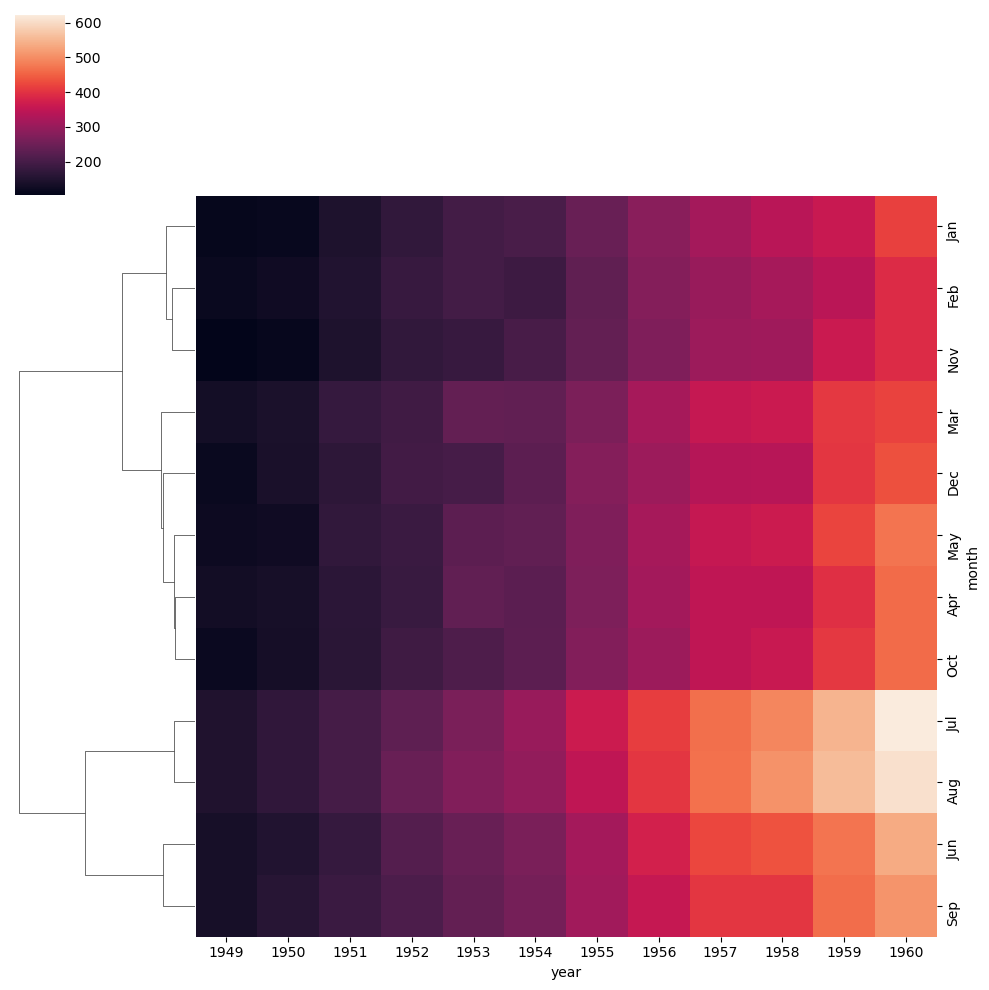

In [212]:
# just cluster by rows or months
sns.clustermap(flight_dframe,col_cluster=False)

**standardize**
since the num of flights increase every year we should set standard scale

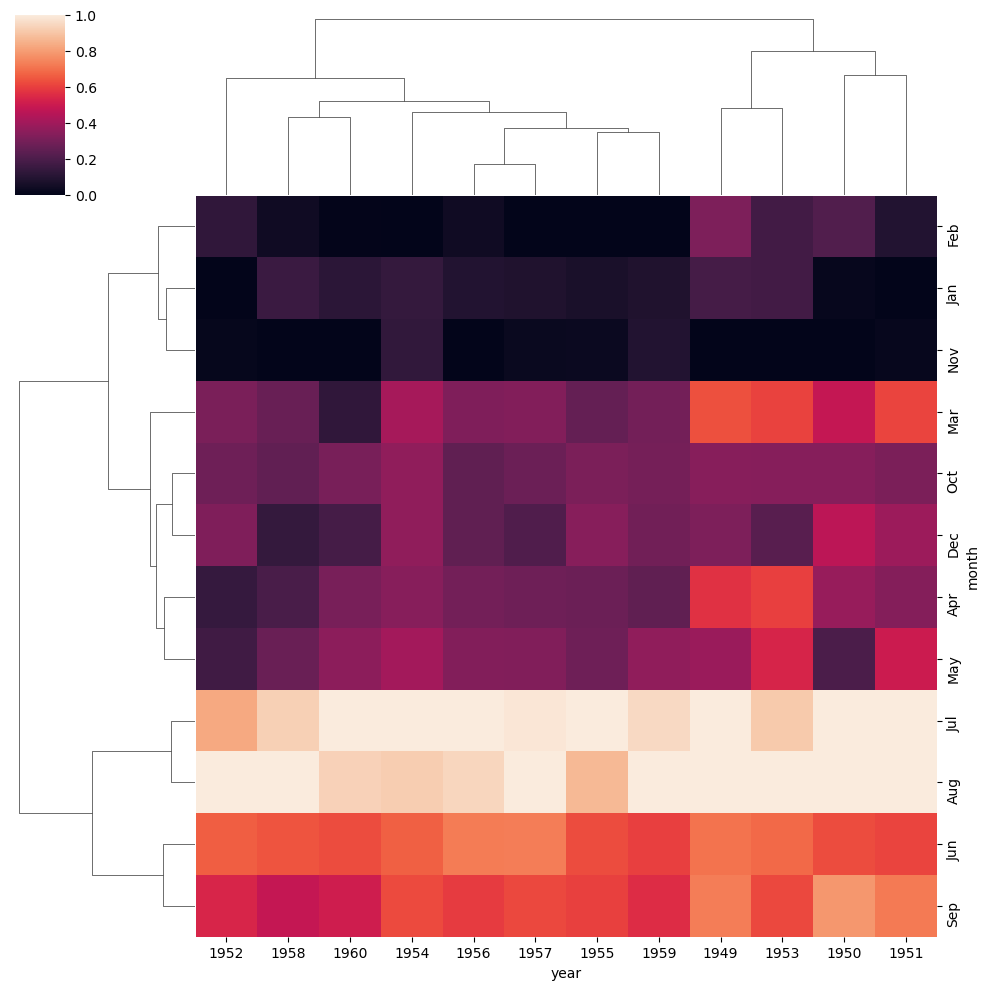

In [218]:
# standard_scale=1 --> standardize by columns or year
sns.clustermap(flight_dframe,standard_scale=1)

**scale by rows**

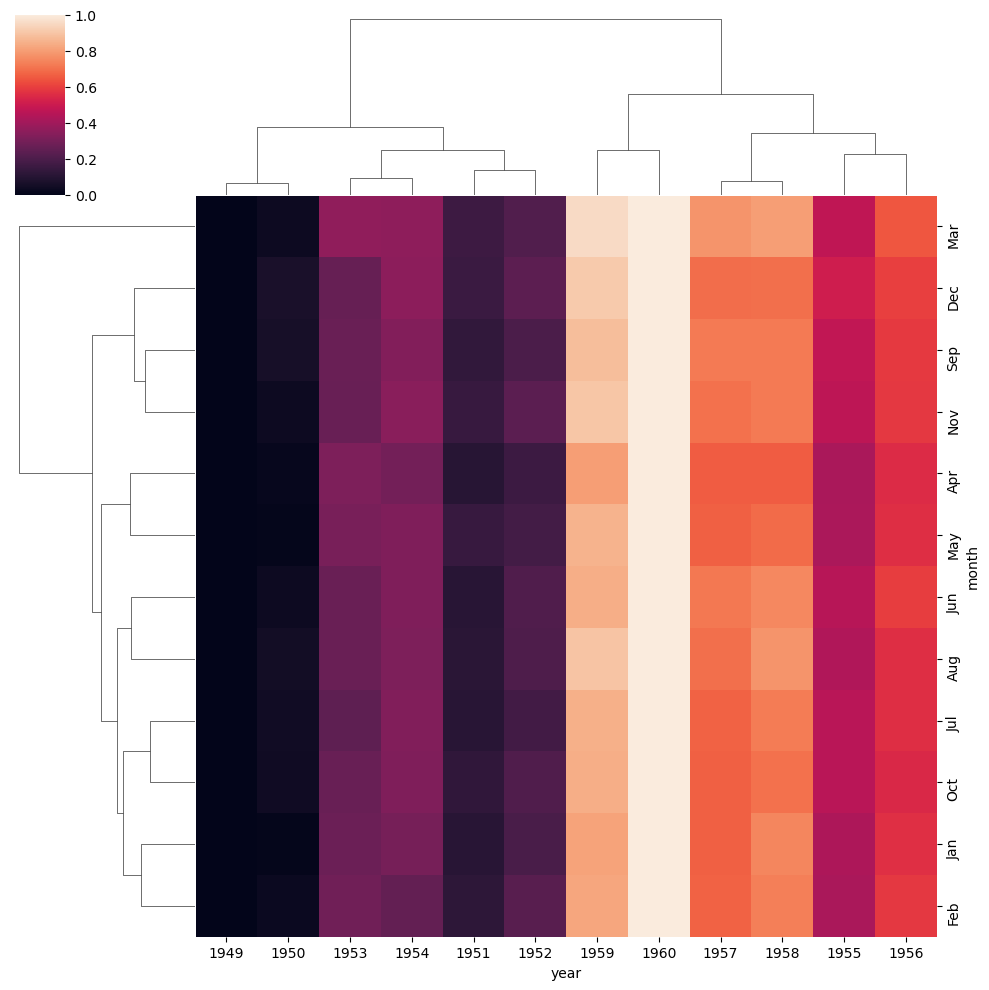

In [223]:
sns.clustermap(flight_dframe,standard_scale=0)

**normalize by Z-score**
subtracts mean and then divides by the standard deviation of each column so the rows will have mean of 0 and variance of 1

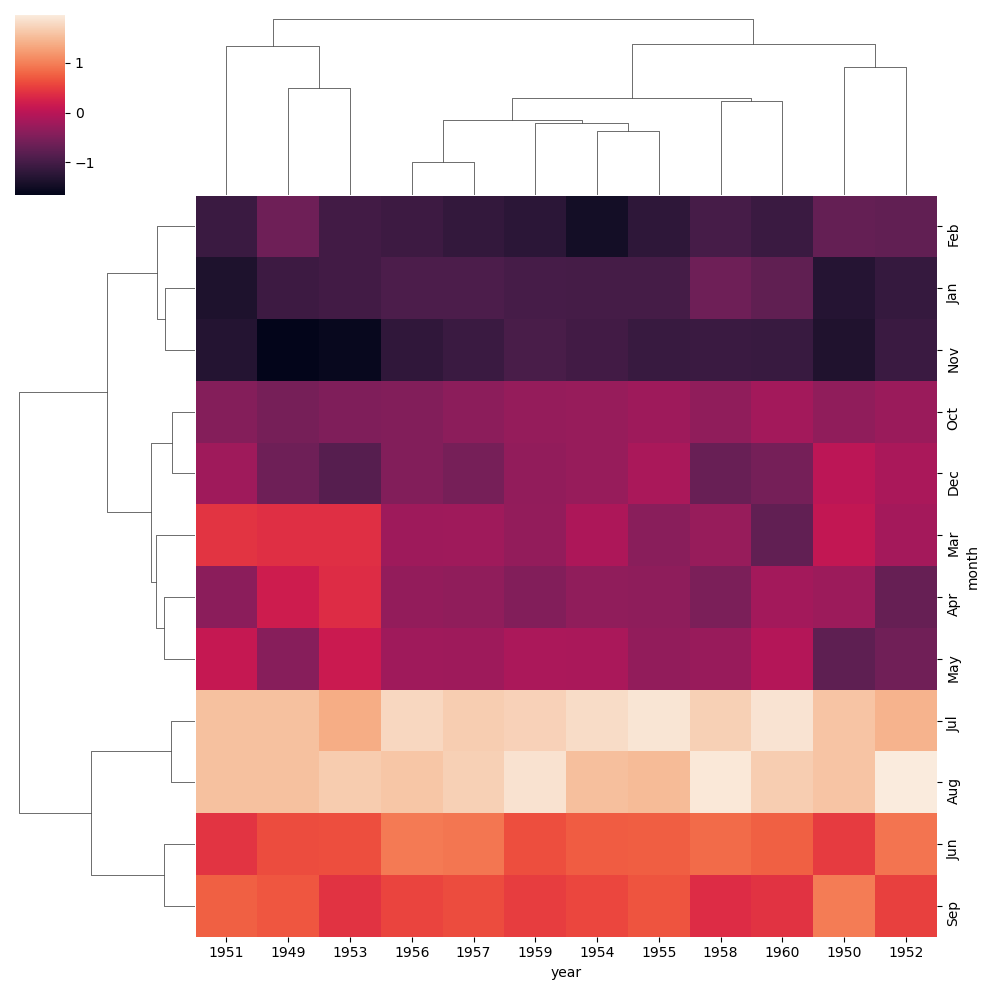

In [227]:

sns.clustermap(flight_dframe,z_score=1)
# in summer months we have higher flights 